# CSDA STAC search: multiple vendors' data at Sites

Summary:  
+ read in a sites geojson
+ compile a STAC search at site for a time period for vendor imagery
+ plot the footprints of the results
+ next step (todo) - how to access the image data for analysis?

#### Resources:
+ https://nasa-impact.github.io/csda-client/latest/examples/search-and-download/#finding-planet-data

| Author | Affiliation | Date |
| ---------------- | ---------------- | ---------------- |
| Paul Montesano, PhD | NASA Goddard Space Flight Center; ESSIC | July 2026 |

In [ ]:
#pip install contextily
#pip install matplotlib_scalebar

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from urllib.parse import quote
import numpy as np

import sys

sys.path.append('/projects/code/csda_summaries/lib')
sys.path.append('/projects/code/geoscitools')
sys.path.append('/home/pmontesa/code/csda_summaries/lib')
sys.path.append('/home/pmontesa/code/geoscitools')

import csdalib
import staclib
import siteslib

from datetime import datetime
from multiprocessing import Pool, cpu_count
from functools import partial
from tqdm import tqdm
import importlib

/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/pyproj/../../.././libtiff.so.6: version `LIBTIFF_4.6.1' not found (required by /app/jupyter/ilab/jupyter-lab/prod/lib/gdalplugins/../libgdal.so.36)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3

## CSDA Evaluation Sites

Our database of `CSDA Evaluation Sites` is a critical & foundational set of information for CSDA SME work. Each site, uniquely identified with a `Site Name` and a specific geographic extent (AOI), provides some sort of radiometric or geometric reference for evaluation commercial imagery.

#### Read in our CSDA sites GeoJSON (AOIs) directly from GitHub

In [63]:
RAW_BASE = 'https://raw.githubusercontent.com/pahbs/csda_summaries/master'
sites_url = f'{RAW_BASE}/sites/eval_sites_aoi.geojson'
SITES_STR = 'eval'
sites_gdf = gpd.read_file(sites_url)
print(f"{sites_gdf.shape[0]} CSDA site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.")

611 CSDA site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.


In [30]:
SITES_STR = 'alaska_agb_validation'
sites_gdf = gpd.read_file(f'../sites/{SITES_STR}_sites.geojson')
sites_gdf['Site Name'] = sites_gdf['site_name']

In [31]:
BUF_KM = 0

In [68]:
DO_SITE_SUBSET = True
RADCALNET = True

In [82]:
if DO_SITE_SUBSET:
    if RADCALNET:
        SITES_STR = 'RadCalNet'
        sites_gdf = sites_gdf[sites_gdf.Source == SITES_STR]
    else:
        #SITENAME = 'Bonanza_Creek'
        SITENAME = 'PICS Libya-4'
        SITENAME = 'La Crau'
        SITES_STR = SITENAME.replace(' ','.')
        sites_gdf = sites_gdf[sites_gdf['Site Name'] == SITENAME]

In [182]:
sites_gdf

,site_id,Site Name abbrev,Site Name,Location Name,Country,Program Use,Longitude,Latitude,Remote Sensing Domain,Priority Level,...,max_view_angle,min_num_acqs,ideal_num_acqs,max_cloud_pct_aoi,max_cloud_pct_scene,contact,reference,notes,area_km2,geometry
10,NaN,Baotou,Baotou,China cal/val,China,CSDA,109.629437,40.851787,Optical Multi/Hyper,high,...,15.0,NaN,NaN,0.0,NaN,brian.n.wenny@nasa.gov,None,None,0.001600,"POLYGON ((109.62968 40.85161, 109.62967 40.851..."
31,NaN,Gobabeb,Gobabeb,Gobabeb,Namibia,CSDA,15.119560,-23.600200,Optical Multi/Hyper,high,...,NaN,NaN,NaN,NaN,NaN,brian.n.wenny@nasa.gov,None,None,28.228936,"POLYGON ((15.14897 -23.60017, 15.14883 -23.602..."
38,NaN,La Crau,La Crau,La Crau,France,CSDA,4.864167,43.558889,Optical Multi/Hyper,high,...,NaN,NaN,NaN,NaN,NaN,brian.n.wenny@nasa.gov,None,None,28.228936,"POLYGON ((4.90129 43.55828, 4.90103 43.55563, ..."
51,NaN,Railroad Valley,Railroad Valley,Nevada,USA,CSDA,-115.690000,38.497000,Optical Multi/Hyper,high,...,NaN,NaN,NaN,NaN,NaN,brian.n.wenny@nasa.gov; shashank.bhushan@nasa.gov,None,15km radius to help characterize fine-scale se...,705.723410,"POLYGON ((-115.51804 38.49495, -115.51914 38.4..."
60,NaN,Sioux Falls,Sioux Falls,South Dakota,USA,CSDA,-96.625990,43.736480,Optical Multi,high,...,NaN,NaN,NaN,NaN,NaN,paul.m.montesano@nasa.gov,None,None,28.228936,"POLYGON ((-96.58877 43.73570, -96.58905 43.733..."
63,NaN,Golmud,Golmud,Tibetan Plateau,China,CSDA,94.328600,36.397700,Optical Multi/Hyper,high,...,NaN,NaN,NaN,NaN,NaN,brian.n.wenny@nasa.gov,None,None,28.228936,"POLYGON ((94.36205 36.39732, 94.36184 36.39467..."


#### Configure site AOIs for display in site maps down below

In [70]:
### Buffer MORE for sites for display
BUF_KM_ADD_FOR_DISPLAY = 0
BUF_KM_TOTAL_FOR_DISPLAY = BUF_KM_ADD_FOR_DISPLAY + BUF_KM

In [71]:
sites_gdf_buf = sites_gdf.to_crs(3857).buffer(BUF_KM_ADD_FOR_DISPLAY * 1000) # add arbitrary buffer to evaluation sites for map display
sites_gdf_buf_display = gpd.GeoDataFrame(sites_gdf.drop(columns=['geometry']), geometry=sites_gdf_buf, crs=sites_gdf_buf.crs).to_crs(4326)
sites_gdf_buf_display = sites_gdf_buf_display[~(sites_gdf_buf_display.geometry.is_empty | sites_gdf_buf_display.geometry.isna())]

# Table of CSDA STAC Collections

Here is what data we can find in the CSDA STAC

In [72]:
import requests
from IPython.display import Markdown, display

STAC_API_URL = 'https://csdap.earthdata.nasa.gov/stac'

# Get collections
response = requests.get(f'{STAC_API_URL}/collections')
data = response.json()

collections = data.get('collections', [])

# Build markdown
markdown_output = f"# CSDA STAC Collections\n\n"
markdown_output += f"**Total Collections:** {len(collections)}\n\n"
markdown_output += "| ID | Title | Description | Temporal Coverage |\n"
markdown_output += "|:---|:---|:---|:---|\n"

for collection in collections:
    col_id = collection.get('id', 'N/A')
    title = collection.get('title', 'N/A')
    description = collection.get('description', 'N/A')
    
    # Truncate and clean description
    if description and description != 'N/A':
        description = description.replace('\n', ' ').replace('\r', '')
        if len(description) > 100:
            description = description[:100] + '...'
        description = description.replace('|', '\\|')
    
    # Get temporal extent with safe None checks
    temporal_str = 'N/A'
    try:
        extent = collection.get('extent')
        if extent and isinstance(extent, dict):
            temporal = extent.get('temporal')
            if temporal and isinstance(temporal, dict):
                intervals = temporal.get('interval', [])
                if intervals and isinstance(intervals, list) and len(intervals) > 0:
                    if intervals[0] and isinstance(intervals[0], list) and len(intervals[0]) > 0:
                        start = intervals[0][0] if intervals[0][0] else 'Unknown'
                        end = intervals[0][1] if len(intervals[0]) > 1 and intervals[0][1] else 'Present'
                        
                        # Format dates nicely
                        if isinstance(start, str) and start not in ['Unknown', 'N/A']:
                            start = start.split('T')[0]
                        if isinstance(end, str) and end not in ['Present', 'N/A']:
                            end = end.split('T')[0]
                        
                        temporal_str = f"{start} to {end}"
    except Exception as e:
        # If anything goes wrong, just leave as N/A
        pass
    
    # Create collection link
    collection_url = f"{STAC_API_URL}/collections/{col_id}"
    col_id_link = f"[{col_id}]({collection_url})"
    
    markdown_output += f"| {col_id_link} | {title} | {description} | {temporal_str} |\n"

# Display in notebook
display(Markdown(markdown_output))

# Save to file
with open('stac_collections.md', 'w') as f:
    f.write(markdown_output)

print("\n✓ Saved to stac_collections.md")

# CSDA STAC Collections

**Total Collections:** 19

| ID | Title | Description | Temporal Coverage |
|:---|:---|:---|:---|
| [umbra](https://csdap.earthdata.nasa.gov/stac/collections/umbra) | Umbra | Umbra Space | 2023-11-02 to 2026-08-09 |
| [desis](https://csdap.earthdata.nasa.gov/stac/collections/desis) | DESIS | Teledyne Brown Engineering, Inc – DESIS | 2018-08-30 to 2024-05-25 |
| [pixxel](https://csdap.earthdata.nasa.gov/stac/collections/pixxel) | Pixxel | Pixxel | 2025-06-21 to 2026-06-13 |
| [planetiq](https://csdap.earthdata.nasa.gov/stac/collections/planetiq) | PlanetiQ | PlanetiQ | 2024-01-18 to 2025-03-24 |
| [satellogic](https://csdap.earthdata.nasa.gov/stac/collections/satellogic) | Satellogic | Satellogic Inc. | 2021-02-02 to 2026-08-09 |
| [airbus-dem](https://csdap.earthdata.nasa.gov/stac/collections/airbus-dem) | Airbus - DEM | Airbus - DEM | 2025-09-19 to 2026-04-02 |
| [geooptics](https://csdap.earthdata.nasa.gov/stac/collections/geooptics) | GeoOptics | geooptics | 2020-01-01 to 2021-04-30 |
| [planet](https://csdap.earthdata.nasa.gov/stac/collections/planet) | Planet | Planet | 2009-03-13 to 2026-05-30 |
| [spire](https://csdap.earthdata.nasa.gov/stac/collections/spire) | Spire | Spire | 2019-11-01 to 2025-08-09 |
| [iceye](https://csdap.earthdata.nasa.gov/stac/collections/iceye) | Iceye | ICEYE US | 2019-10-17 to 2026-08-09 |
| [capellaspace](https://csdap.earthdata.nasa.gov/stac/collections/capellaspace) | CapellaSpace | capellaspace | 2020-12-26 to 2026-08-08 |
| [tomorrow](https://csdap.earthdata.nasa.gov/stac/collections/tomorrow) | Tomorrow | The Tomorrow Companies Inc. | 2023-06-24 to 2026-02-22 |
| [pgc-earthdem](https://csdap.earthdata.nasa.gov/stac/collections/pgc-earthdem) | EarthDEM | EarthDEM | 2002-02-06 to 2024-07-01 |
| [maxar-sdx](https://csdap.earthdata.nasa.gov/stac/collections/maxar-sdx) | Maxar DEM | Maxar Technologies – Precision 3D | 2008-01-18 to 2025-05-26 |
| [airbus](https://csdap.earthdata.nasa.gov/stac/collections/airbus) | Airbus U.S.- SAR | Airbus U.S. | 2007-11-19 to 2026-08-04 |
| [maxar-legion](https://csdap.earthdata.nasa.gov/stac/collections/maxar-legion) | Maxar Legion | Maxar Technologies Inc. | 2024-09-11 to 2026-08-07 |
| [airbus-optical](https://csdap.earthdata.nasa.gov/stac/collections/airbus-optical) | Airbus U.S.- Optical | Airbus U.S.- Optical | 2021-08-15 to 2026-07-08 |
| [blacksky](https://csdap.earthdata.nasa.gov/stac/collections/blacksky) | BlackSky | BlackSky Technology, Inc. | 2019-05-07 to 2026-08-08 |
| [ghgsat](https://csdap.earthdata.nasa.gov/stac/collections/ghgsat) | GHGSat | GHGSat | 2021-01-03 to 2026-08-02 |



✓ Saved to stac_collections.md


### Create site dicts for all sites

In [73]:
site_dicts = staclib.create_site_dict_from_gdf(sites_gdf, site_name_field = 'Site Name', buffer_degrees=0)

In [74]:
len(site_dicts)

6

# Multiprocess search across all CSDA Evaluation Sites for a vendor

### Configure search

In [39]:
TODAY = datetime.now().strftime('%Y-%m-%d')
START_OF_COMMERCIAL_ERA = '1999-01-01'

In [40]:
# Alaska search
COLLECTION_LIST = ['planet','airbus-optical','satellogic','maxar-legion']
YEAR = 2019 #2024
START_DATE = f'{YEAR}-01-01'
#START_DATE = START_OF_COMMERCIAL_ERA
END_DATE = f'{YEAR+1}-01-01'
#END_DATE = '2019-12-31'
MONTH_LIST = [6,7,8]

In [97]:
# Misc search
COLLECTION_LIST = ['planet','airbus-optical','satellogic','maxar-legion','pixxel']
YEAR = 'allyears'
START_DATE = START_OF_COMMERCIAL_ERA
END_DATE = TODAY
#END_DATE = '2019-12-31'
MONTH_LIST = list(range(1,12+1))

In [98]:
CSDA_EVAL_SITE_ITEMS = list(site_dicts.items())

### Multiprocess SDX search across CSDA Eval sites

In [99]:
import importlib
importlib.reload(staclib)

<module 'staclib' from '/home/pmontesa/code/csda_summaries/lib/staclib.py'>

In [102]:
search_func = partial(staclib.stac_search_site, end_date=END_DATE, start_date=START_DATE,  months=MONTH_LIST,
                      collections=COLLECTION_LIST
                     )
#search_func = partial(search_site, today=today, start_date='2010-01-01', collections=['maxar'])

n_processes = max(1, cpu_count() - 1)
print(f"Using {n_processes} processes to search {len(CSDA_EVAL_SITE_ITEMS)} sites\n")

# Run with progress bar
with Pool(processes=n_processes) as pool:
    results = list(tqdm(
        pool.imap(search_func, CSDA_EVAL_SITE_ITEMS),
        total=len(CSDA_EVAL_SITE_ITEMS),
        desc="Searching sites"
    ))

# Collect and report results
stac_gdf_list = []
stac_items_list = []
print("\nResults by site:")
for site_name, gdf, items, message in results:
    print(f"  {site_name}: {message}")
    if gdf is not None:
        stac_gdf_list.append(gdf)
        stac_items_list.extend(items)

# Combine
if stac_gdf_list:
    stac_gdf = pd.concat(stac_gdf_list, ignore_index=True)
    print(f"\n{'='*60}")
    print(f"Total: {len(stac_gdf)} items from {stac_gdf['site_name'].nunique()} sites")
    print(f"{'='*60}")
    print("\nItems per site:")
    print(stac_gdf['site_name'].value_counts())
else:
    print("\nNo items found")
    stac_gdf = gpd.GeoDataFrame()

Using 39 processes to search 6 sites



Searching sites: 100%|██████████| 6/6 [00:58<00:00,  9.82s/it]



Results by site:
  Baotou: Found 3728 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Gobabeb: Found 3784 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  La Crau: Found 2524 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Railroad Valley: Found 10185 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Sioux Falls: Found 1430 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Golmud: No items found

Total: 21651 items from 5 sites

Items per site:
Railroad Valley    10185
Gobabeb             3784
Baotou              3728
La Crau             2524
Sioux Falls         1430
Name: site_name, dtype: int64


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_2373781/3951964647.py:21: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.



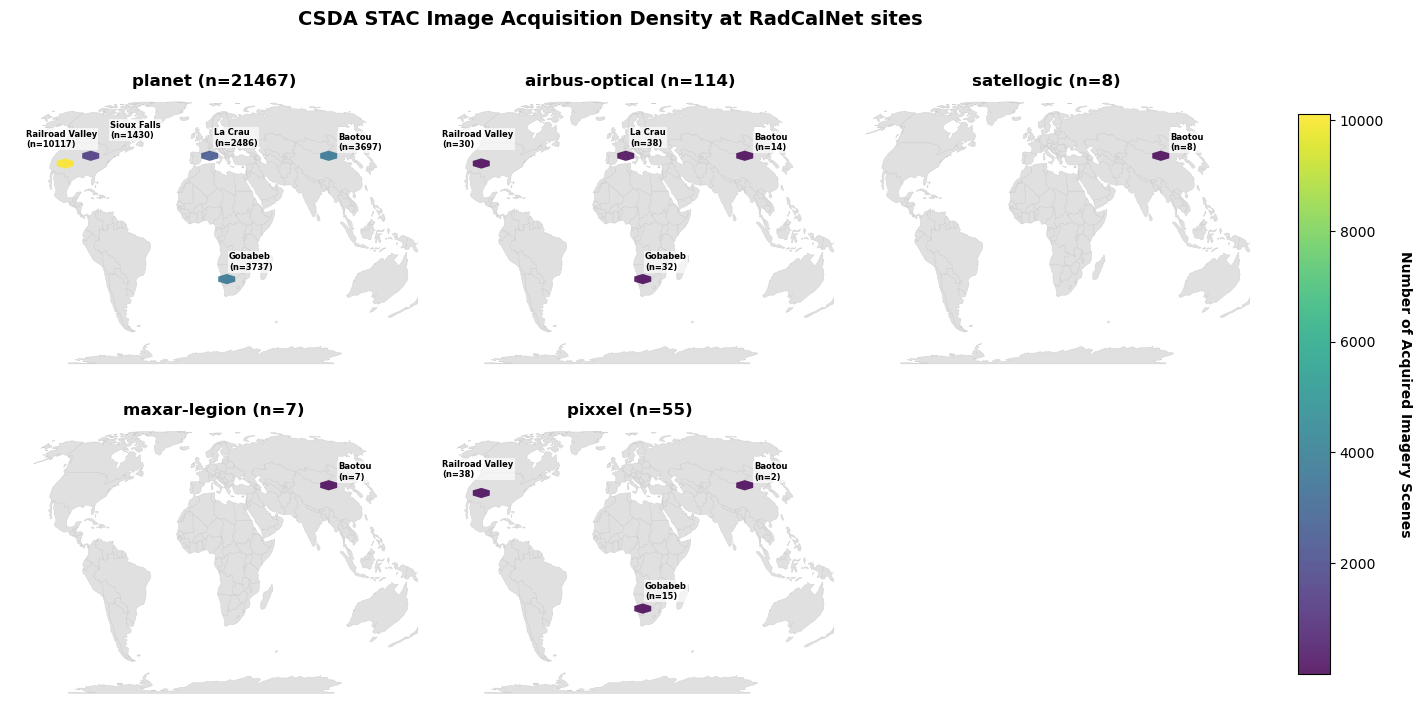

In [200]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Polygon

# 1. Define target Eckert VI projection string
eckert_vi_crs = '+proj=eck6 +lon_0=0 +x_0=0 +y_0=0 +ellps=WGS84 +datum=WGS84 +units=m +no_defs'

# 2. Build local offline global boundary canvas 
try:
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
except (AttributeError, FileNotFoundError):
    world_box = Polygon([(-180, -90), (-180, 90), (180, 90), (180, -90)])
    world = gpd.GeoDataFrame(index=[0], crs='EPSG:4326', geometry=[world_box])

world_projected = world.to_crs(eckert_vi_crs)
xmin, ymin, xmax, ymax = world_projected.total_bounds

# 3. Process STAC centroids safely
heatmap_df = stac_gdf.copy()
heatmap_df['centroid_geom'] = heatmap_df['geometry'].centroid
centroid_gdf = gpd.GeoDataFrame(heatmap_df, geometry='centroid_geom', crs=stac_gdf.crs)
centroid_projected = centroid_gdf.to_crs(eckert_vi_crs)

centroid_projected['x'] = centroid_projected.geometry.x
centroid_projected['y'] = centroid_projected.geometry.y

# Drop rows without site names, then take the first instance of each site to avoid duplicate overlapping text
sites_unique = centroid_projected.dropna(subset=['site_name']).drop_duplicates(subset=['site_name'])

# 4. Configure layout structures
collections = [c for c in centroid_projected['collection'].unique() if pd.notna(c)]
num_collections = len(collections)
# --- UPDATE IN SECTION 4: Extract tight landmass bounds instead of global limits ---
# Get the strict min/max spatial coordinates of actual land geometries
xmin_land, ymin_land, xmax_land, ymax_land = world_projected.total_bounds

ncols = 3 if num_collections > 1 else 1
nrows = (num_collections + ncols - 1) // ncols

# Adjust fig size dynamically and reserve space on the right for the colorbar
fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols, 
    figsize=(16, 4 * nrows),
    facecolor='white'
)

if num_collections == 1:
    axes = np.array([axes])
else:
    axes = axes.flatten()

# Track hexbin plot objects to link the colorbar scale
hb_objects = []

# 5. Build the Hexbin subplots
for i, col_name in enumerate(collections):
    ax = axes[i]
    ax.set_facecolor('white') # Water is white
    
    # Base landmass layer (Light gray)
    world_projected.plot(ax=ax, color='#e0e0e0', edgecolor='#cccccc', linewidth=0.3)
    
    # Filter collection data
    col_data = centroid_projected[centroid_projected['collection'] == col_name]
    num_col_images = col_data.shape[0]  # Total images in this specific collection
    
    
    if not col_data.empty:
        # Create Hexagonal grid
        # gridsize=40 defines the resolution (higher number = smaller hex sizes)
        # mincnt=1 ensures empty regions stay white instead of gray
        hb = ax.hexbin(
            col_data['x'], col_data['y'],
            gridsize=30,
            cmap='viridis', # High visibility color scale: Yellow (low) to Red (high)
            mincnt=1,
            edgecolors='none',
            alpha=0.85,
            extent=[xmin_land, xmax_land, ymin_land, ymax_land] # LOCKS GRID SHIFTING
        )
        hb_objects.append(hb)

    # Calculate image counts per site within this specific collection subplot
    site_counts = col_data['site_name'].value_counts().to_dict()

    # --- NEW STEP: Overlay Site Points and Text Labels ---
    # Only label sites that actually have data present in this specific collection subplot
    active_sites_in_col = col_data['site_name'].unique()
    col_sites = sites_unique[sites_unique['site_name'].isin(active_sites_in_col)]
    
    # 1. Plot a tiny anchor dot for the site location
    ax.scatter(col_sites['x'], col_sites['y'], color='blue', s=15, zorder=5, edgecolors='white', linewidth=0.5, alpha=0)
    
    # 2. Iterate and draw text string labels
    for _, row in col_sites.iterrows():
        s_name = row['site_name']
        n_images_site = site_counts.get(s_name, 0)
            
        # Format label string to include data count summary
        label_text = f"{s_name}\n(n={n_images_site})"

        # --- SIMPLE OFFSET TUNING ---
        if "Railroad Valley" in s_name:
            x_offset, y_offset = -25, 10    # Shift slightly left and up
            align = "right"                # Align text box from the right edge
        elif "Sioux Falls" in s_name:
            x_offset, y_offset = 15, 10     # Shift slightly right and up
            align = "left"                 # Align text box from the left edge
        else:
            x_offset, y_offset = 5, 5     # Standard fallback position
            align = "left"
        
        ax.annotate(
            text=label_text,
            xy=(row['x'], row['y']),
            xytext=(x_offset, y_offset), #xytext=(5, 5),               # Shorthand pixel offset: 5 pixels right, 5 pixels up from dot
            textcoords="offset points",
            fontsize=6,
            fontweight='bold',
            color='black',
            zorder=6,
            # Background bounding box creates a subtle white halo around text for readability over red bins
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.65)
        )

    # FIXED EXTENT CLIPPING: Lock zoom closely to landmass boundaries
    # This automatically crops off the empty ocean gaps on the far left and right edges
    ax.set_xlim(xmin_land * 0.75, xmax_land * 0.85) 
    ax.set_ylim(ymin_land * 1.02, ymax_land * 1.02)

    ax.set_title(f"{col_name} (n={num_col_images})", fontsize=12, fontweight='bold', pad=10)
    ax.axis('off')

# Clean up empty axes slots
for j in range(num_collections, len(axes)):
    fig.delaxes(axes[j])

# 6. Construct unified colorbar scales dynamically
if hb_objects:
    # FIXED: Added the missing bracket to create a valid list concatenation: + [0]
    max_val = max([h.get_array().max() for h in hb_objects] + [0])
    for hb in hb_objects:
        hb.set_clim(1, max_val)
        
    # Place colorbar neatly on the right side of the entire layout matrix
    cbar_ax = fig.add_axes([0.93, 0.15, 0.02, 0.7])
    cbar = fig.colorbar(hb_objects[0], cax=cbar_ax) # Linked directly to the base hexbin map scale
    cbar.set_label('Number of Acquired Imagery Scenes', rotation=270, labelpad=20, fontweight='bold')


plt.suptitle(f'CSDA STAC Image Acquisition Density at {SITES_STR} sites', fontsize=14, fontweight='bold', y=0.98)
#plt.subplots_adjust(right=0.90, wspace=0.15, hspace=0.3)
plt.subplots_adjust(right=0.90, wspace=0.02, hspace=0.15)
plt.show()


In [205]:
heatmap_df[heatmap_df.collection == 'maxar-legion'].start_datetime

3312    2024-11-20T03:35:59.871865Z
3533    2025-09-06T03:21:36.246792Z
3544    2025-08-29T02:23:28.246798Z
3620    2025-06-03T03:18:25.871847Z
3654    2025-04-24T00:33:42.622158Z
3693    2025-03-14T03:39:53.996935Z
3719    2024-11-20T03:35:59.871865Z
Name: start_datetime, dtype: object

/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_2373781/2713790140.py:22: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.


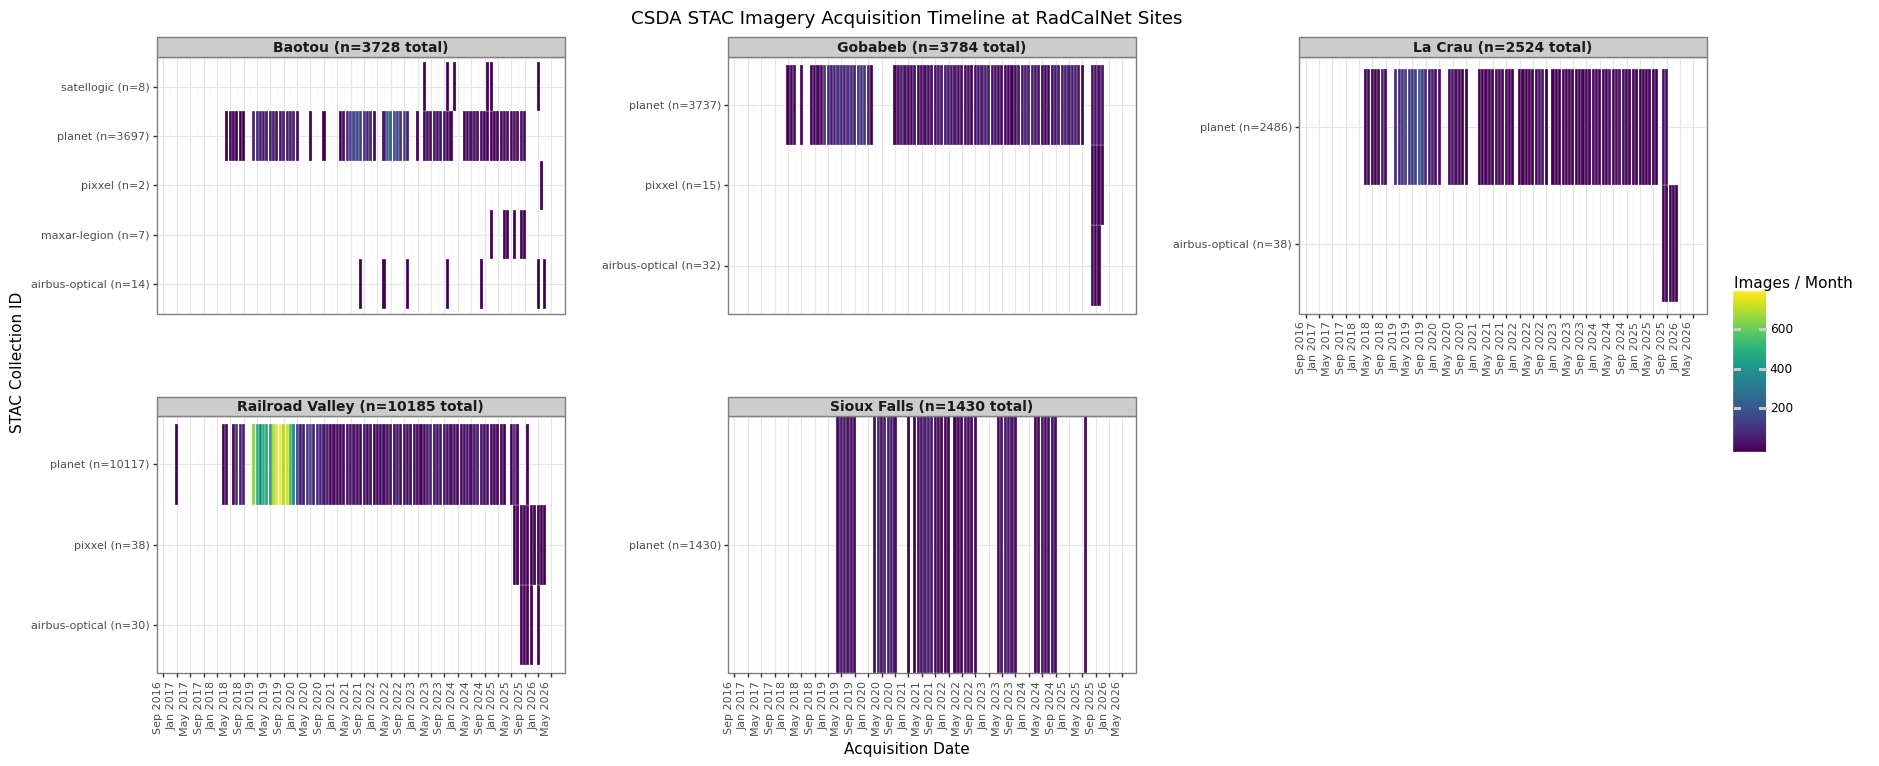

In [210]:
import pandas as pd
import numpy as np
from plotnine import (
    ggplot, aes, geom_tile, facet_wrap, 
    theme_minimal, theme, element_text, 
    labs, scale_fill_cmap, scale_x_date
)

# 1. Prepare data and apply conditional fallback rules for maxar-legion
heatmap_df = stac_gdf.copy()

# Dynamically select 'start_datetime' if collection is maxar-legion, else 'datetime'
heatmap_df['datetime_target'] = np.where(
    heatmap_df['collection'].str.contains('maxar-legion', case=False, na=False),
    heatmap_df['start_datetime'],
    heatmap_df['datetime']
)

# Parse the resolved target timestamps to pandas datetime objects safely
heatmap_df['date_parsed'] = pd.to_datetime(heatmap_df['datetime_target'], errors='coerce')
heatmap_df = heatmap_df.dropna(subset=['date_parsed', 'site_name', 'collection'])
heatmap_df['acquisition_month'] = heatmap_df['date_parsed'].dt.to_period('M').dt.to_timestamp()

# 2. Compute dynamic label extensions using mapping tables
# A. Get total image counts for each physical site (Facet strip text)
site_totals = heatmap_df['site_name'].value_counts().to_dict()
heatmap_df['site_labeled'] = heatmap_df['site_name'].map(
    lambda x: f"{x} (n={site_totals.get(x, 0)} total)"
)

# B. Get unique image counts per collection row within each site
row_counts = heatmap_df.groupby(['site_labeled', 'collection']).size().to_dict()
heatmap_df['collection_labeled'] = heatmap_df.apply(
    lambda r: f"{r['collection']} (n={row_counts.get((r['site_labeled'], r['collection']), 0)})", axis=1
)

# 3. Aggregate data down to month intervals using the new label schemas
summary_df = (
    heatmap_df.groupby(['site_labeled', 'collection_labeled', 'acquisition_month'])
    .size()
    .reset_index(name='acquisition_count')
)

# 4. Create the timeline heatmap plot
heatmap_plot = (
    ggplot(summary_df, aes(x='acquisition_month', y='collection_labeled', fill='acquisition_count'))
    + geom_tile(color='white', size=0.1)
    + facet_wrap('~site_labeled', scales='free_y', ncol=3) # free scale recalculates row steps per site cleanly
    + scale_fill_cmap(cmap_name='viridis') 
    + scale_x_date(date_labels='%b %Y', date_breaks='4 months')
    + labs(
        title=f'CSDA STAC Imagery Acquisition Timeline at {SITES_STR} Sites',
        x='Acquisition Date',
        y='STAC Collection ID',
        fill='Images / Month'
    )
    + theme_bw()
    + theme(
        axis_text_x=element_text(rotation=90, hjust=1, size=8),
        axis_text_y=element_text(size=8),
        figure_size=(20, 8),
        legend_position='right',
        strip_text=element_text(size=10, fontweight='bold'),
        subplots_adjust={'hspace': 0.4, 'wspace': 0.4} # Left more wspace room for long row titles
    )
)

print(heatmap_plot)


## Save items & footprints: 

SDX STAC search results to JSON & geopackage

In [105]:
from pystac import ItemCollection

ic = ItemCollection(stac_items_list)
ic.save_object(f"stac_items_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.json")

In [106]:
stac_gdf = stac_gdf.drop(columns=[col for col in stac_gdf.columns if 'asset' in col])

# Convert list columns to strings
stac_gdf_copy = stac_gdf.copy()
for col in stac_gdf_copy.columns:
    if stac_gdf_copy[col].apply(lambda x: isinstance(x, list)).any():
        stac_gdf_copy[col] = stac_gdf_copy[col].apply(lambda x: str(x) if isinstance(x, list) else x)
        
stac_gdf_copy.to_file(f"stac_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.gpkg")

## Plot maps of sites and their acqs (static)

## Overview map of STAC collections at evaluation sites

/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 27 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 27 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 17 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 27 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tenso

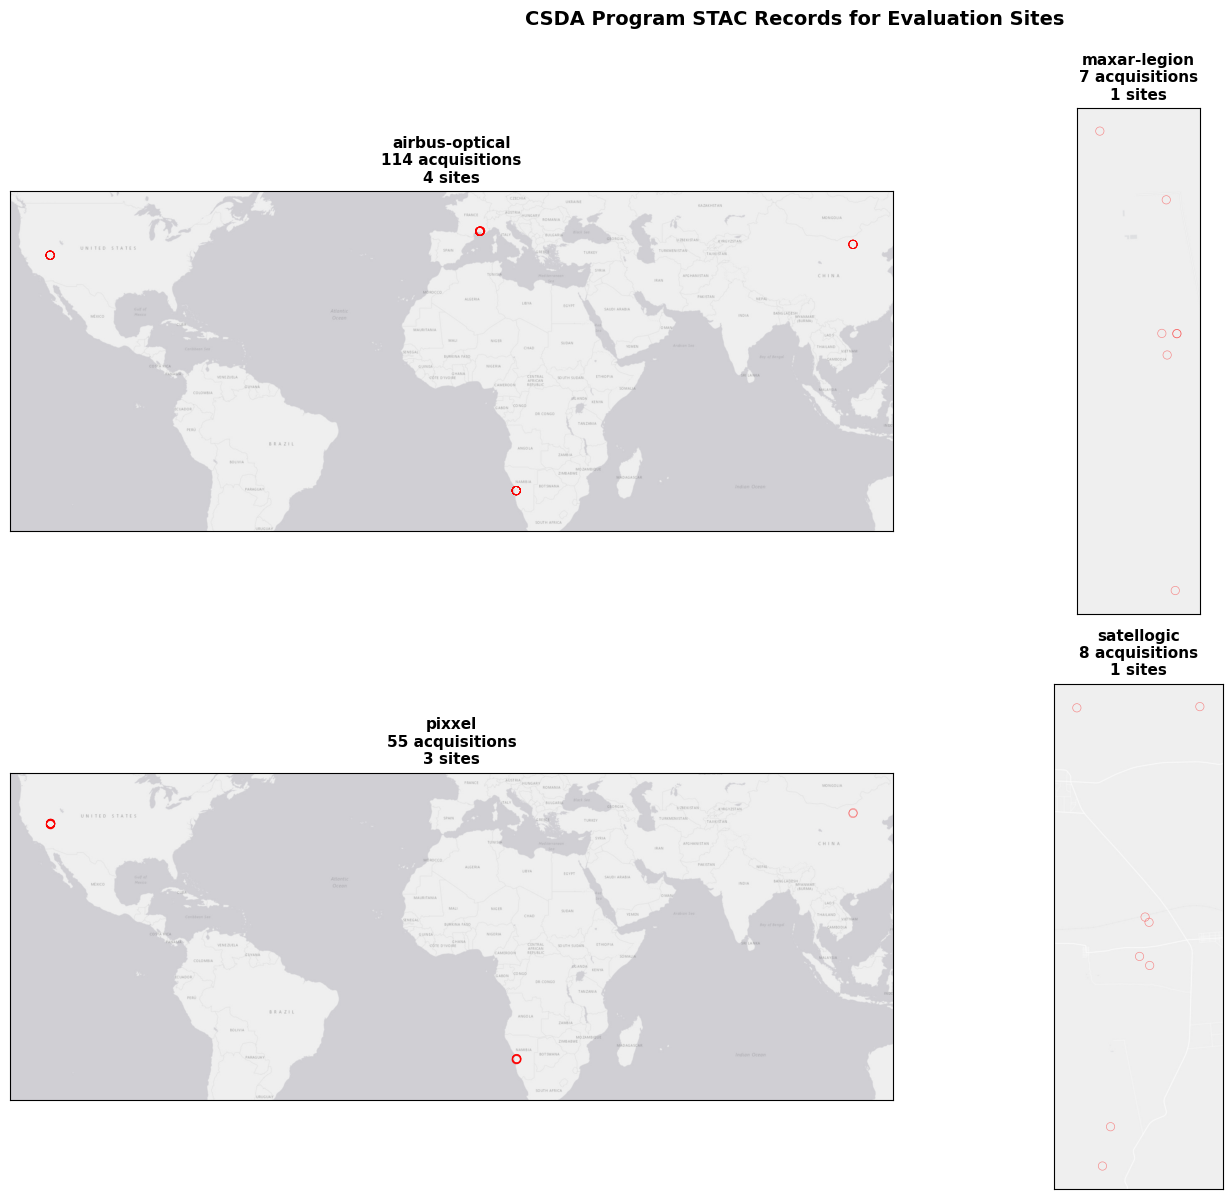

In [85]:
fig = staclib.plot_collections_map(stac_gdf, show_stats=True)
plt.show()

## Testing this : resulting GDF not yet saved

In [86]:
def crosswalk_stac_gdf(gdf: gpd.GeoDataFrame, cloud_max: float = None) -> gpd.GeoDataFrame:
    """
    Dynamically identifies vendor-specific STAC fields and harmonizes them 
    into standard fields: 'unified_satellite_id' and 'unified_cloud_cover'.
    """
    # Create a shallow copy to prevent altering original dataframe in-place
    df = gdf.copy()
    
    # 1. Define search keywords for metadata clustering
    id_keywords = ['platform', 'instrument', 'satellite', 'constellation', 'mission','providor']
    cloud_keywords = ['cloud', 'cloud_cover', 'cloud_percent', 'cloud_pc']
    
    # 2. Extract matching columns from the dataframe
    id_cols = [c for c in df.columns if any(k in c.lower() for k in id_keywords)]
    cloud_cols = [c for c in df.columns if any(k in c.lower() for k in cloud_keywords)]
    
    # 3. Create the unified 'satellite ID' field
    # Coalesces (combines) available id info from best metadata fields into one string
    if id_cols:
        # Standard priority ordering if multiple are found
        priority_order = ['platform', 'eo:instrument', 'instruments', 'constellation']
        sorted_id_cols = sorted(id_cols, key=lambda x: next((i for i, p in enumerate(priority_order) if p in x), len(priority_order)))
        
        # Concatenate multi-instrument descriptions safely if columns overlap
        df['unified_satellite_id'] = df[sorted_id_cols].astype(str).agg(' | '.join, axis=1)
        # Clean up string conversions of null entries
        df['unified_satellite_id'] = df['unified_satellite_id'].str.replace('nan', '').str.strip(' |')
    else:
        df['unified_satellite_id'] = 'Unknown Satellite'

    # 4. Create the unified 'cloud cover' field
    if cloud_cols:
        # Take the first column that has data or average them out depending on preference.
        # Here we prioritize 'eo:cloud_cover' if present, otherwise fallback to the first available match.
        primary_cloud = next((c for c in cloud_cols if 'eo:' in c or 'cover' in c), cloud_cols[0])
        df['unified_cloud_cover'] = pd.to_numeric(df[primary_cloud], errors='coerce')
    else:
        df['unified_cloud_cover'] = 0.0 # Default value if no cloud field exists

    # 5. Optional Filter Application (Integrated helper step)
    if cloud_max is not None:
        df = df[df['unified_cloud_cover'] < cloud_max]

    return df


### Plot site maps for acquisitions

In [87]:
CLOUD_MAX = 1 # for STAC records across multiple vendor, there are different cloud field names - need to crosswalk some key fields first to then more easily filter downstream

In [88]:
gdf_to_plot = crosswalk_stac_gdf(stac_gdf, cloud_max=CLOUD_MAX)

In [89]:
# # 1. Find all columns that contain 'cloud' in their name
# cloud_cols = [col for col in stac_gdf.columns if 'cloud' in col]

# # 2. Check if the value is less than CLOUD_MAX across those columns
# #    .any(axis=1) acts like the OR (|) operator across the selected columns
# gdf_to_plot = stac_gdf[stac_gdf[cloud_cols].lt(CLOUD_MAX).any(axis=1)]
gdf_to_plot.shape

(132, 56)

In [90]:
import importlib
importlib.reload(csdalib)

<module 'csdalib' from '/home/pmontesa/code/csda_summaries/lib/csdalib.py'>

In [91]:
BUF_KM_TOTAL_FOR_DISPLAY

0

KeyboardInterrupt: 

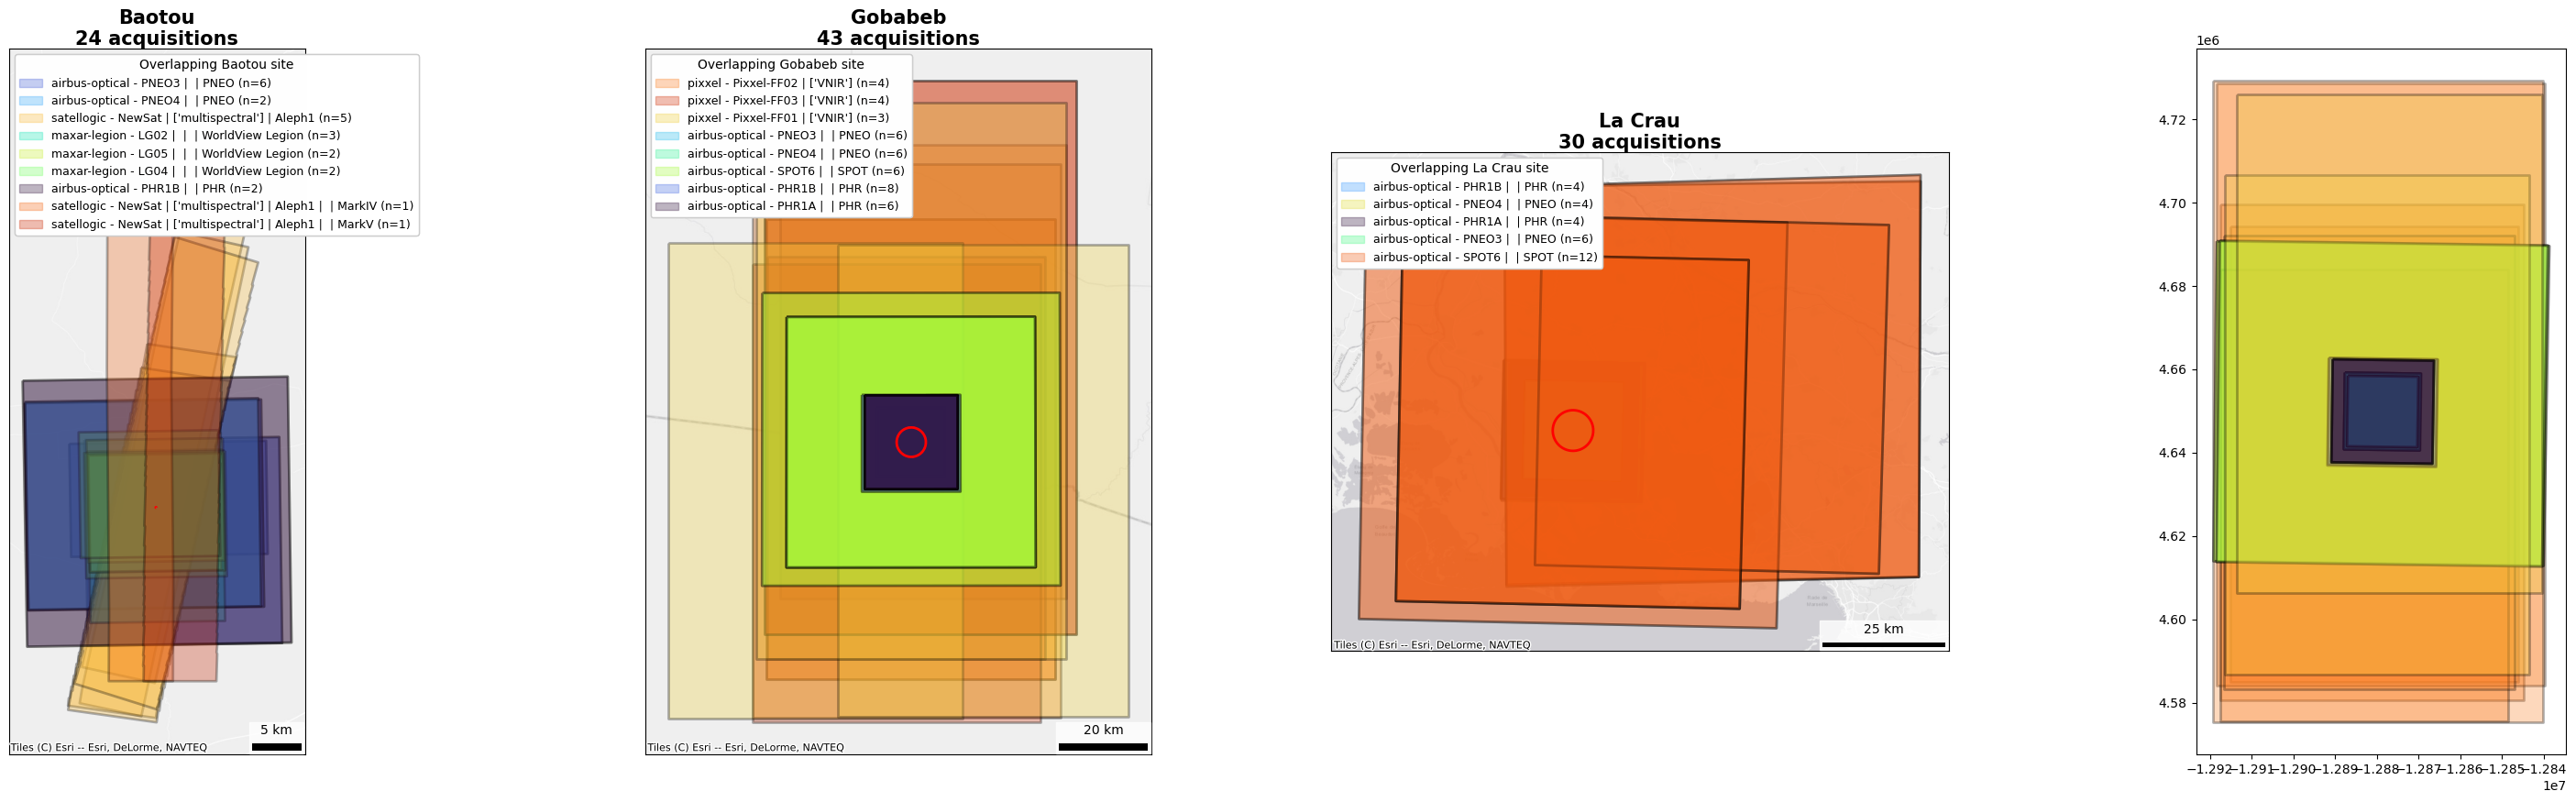

In [202]:
# Define sites to plot
sites_to_plot = sorted([site for site in gdf_to_plot.site_name.unique() if site != 'Not CSDA Eval Site'])

# Create grid
n_sites = len(sites_to_plot)

if n_sites > 5:
    n_cols = 5
else:
    n_cols = n_sites
    
n_rows = int(np.ceil(n_sites / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))

# Flatten axes
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for idx, site_name in enumerate(sites_to_plot):
    csdalib.plot_site_coverage(
        site_name,
        gdf_to_plot,
        sites_gdf,
        BUF_KM_TOTAL_FOR_DISPLAY,
        sites_buf_gdf=sites_gdf_buf_display,
        site_name_field='site_name',
        id_field='id',
        affiliation_field='collection',
        constellation_field='unified_satellite_id',
        ax=axes[idx],
    )

# Hide unused subplots
for idx in range(len(sites_to_plot), len(axes)):
    axes[idx].set_visible(False)

# Add main title
plt.suptitle(f"Imagery\nmonths {MONTH_LIST} | {pd.to_datetime(START_DATE).year} - {pd.to_datetime(END_DATE).year}", fontsize=14, fontweight='bold', y=0.995)

plt.tight_layout()
plt.show()

## Heatmaps provides info on amount of overlap at a site

#### static, all sites for each collection

In [93]:
# Use it
all_grids, fig = staclib.create_acquisition_heatmap_multi(
    stac_gdf,
    sites_gdf,
    sites_gdf_buf_display,
    site_name_field='site_name',
    site_name_field_sites='Site Name',
    # collections=['planet', 'satellogic'],
    # sites=['PICS Libya-4', 'Casablanca'],
    collections=COLLECTION_LIST,
    sites=None,
    grid_size=0.05,
    cmap='magma'
)

plt.show()

Calculating global count range...
Global count range: 1 - 38


/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 21 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 21 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 21 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
/panfs/ccds02/app/modules/jupyter/ilab/tensorflow-kernel/lib/python3.8/site-packages/contextily/tile.py:581: UserWarning: The inferred zoom level of 21 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)
Exception ignored in: <function tqdm.__del__

Error in callback <function _draw_all_if_interactive at 0x14fc10c2e940> (for post_execute):


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x14fc00806b80> (for post_execute):



KeyboardInterrupt



#### interactive for 1 site, collection

In [ ]:
m, grid_gdf = staclib.create_interactive_heatmap(
    stac_gdf,
    collection_name=COLLECTION_LIST[0],
    grid_size=0.01,
    cmap='magma',
    site_name='Boston'
)

# m.save('heatmap.html')
m